# From HCD absorbers to the public likelihood: a tutorial for `hcd_priya`

**UNAPPROVED (PI to review).** This notebook has three parts.

1. **Scientific motivation.** The Lyman-alpha forest and the high-column-density (HCD) absorbers on the same
   sightlines: Lyman limit systems (LLS), sub-damped and damped Lyman-alpha absorbers (subDLAs, DLAs).
2. **The emulator.** What the published model `hcd_priya` 1.0.0 returns: the flux power spectrum (P1D) of four
   classes of sightline, the incidence of the absorbers, and a mixture of the classes.
3. **The public likelihood and the mock-recovery example.** The package's Gaussian likelihood on the mock of the
   repository's example, at the mock's truth, and the stored result of that example redrawn. Nothing is fitted.

**To run it:** `pip install "hcd-priya[tutorials]"` in Python 3.11 or later, then open this file with Jupyter. The
trained model comes with the package.

## Set-up

**UNAPPROVED (PI to review).** Run this notebook from a clone of the repository, from the folder `notebooks/tutorial/`,
in an environment with `pip install "hcd-priya[tutorials]"`. The trained model comes with the package.

Three figures are drawn by the figure scripts of the clone (`scripts/figures/`), and Part III uses the example of
the clone (`examples/mock_recovery.py`) with the example data set of the release. Download that data set and unpack
it beside this notebook once:

```bash
curl -L -O https://github.com/jibanCat/hcd_priya/releases/download/v1.0.0/hcd_priya_example_download.tar.gz
tar -xzf hcd_priya_example_download.tar.gz
```

The example checks each file of that folder when it opens it.

In [1]:
import os
import subprocess
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display

import hcd_analysis
import hcd_analysis.predictor as hp
from hcd_analysis import likelihood

os.makedirs("tutorial_output", exist_ok=True)  # the figures that the released scripts write go here
print("hcd_analysis", hcd_analysis.__version__)

hcd_analysis 1.0.0


## Part I. Scientific motivation

**UNAPPROVED (PI to review).**

**Fig. 1.** PLACEHOLDER: the image from the Leinweber talk (the PI supplies the file and its terms).

**UNAPPROVED (PI to review).** The figure is to show one quasar sightline: the Lyman-alpha forest, and the
absorbers of high column density on the same sightline, a Lyman limit system (LLS), a sub-damped and a damped
Lyman-alpha absorber (subDLA, DLA) with their damping wings.

### Three classes of absorber

**UNAPPROVED (PI to review).** The package sorts absorbers by their neutral hydrogen column density $N_\mathrm{HI}$
into three classes, LLS, subDLA and DLA. A sightline belongs to
the class of its strongest absorber; a sightline with no such absorber is called clean.

### Why the forest and the strong absorbers are usually treated apart

**UNAPPROVED (PI to review).**

- *In observations.* DLAs are found one by one in the spectra and are masked, or their damping wings are fitted.
  LLS are not identified one by one at the resolution of a survey spectrum.
- *In simulations.* The strong absorbers depend on self-shielding and on resolution, and emulators of the forest
  are trained on spectra with the strong absorbers removed.

The two treatments meet in the one-dimensional flux power spectrum (P1D), which is measured on the spectra as
they are.

### What is left in the P1D

**UNAPPROVED (PI to review). HCD contamination is not negligible for small-scale Lyman-alpha cosmology.**

PLACEHOLDER: the statements of Ho et al. (2026) and of the DESI DR1 analysis (Chaves-Montero et al. 2026) on the
absorbers that remain in a measured P1D and on the scales they affect, quoted with their references. Each
sentence is to be checked against its paper before it is written here.

References to be quoted: Ho et al., JCAP 2026 (07) 094; Chaves-Montero et al., JCAP 2026 (06) 040; the DESI DR1
measurements of the P1D, Karacayli et al. (2025) and Ravoux et al. (2025).

## Part II. The emulator

**UNAPPROVED (PI to review).** The published model was trained on the PRIYA suite of hydrodynamical simulations.
Given nine cosmological and astrophysical parameters, a redshift and a mean flux, it returns the P1D of four
classes of sightline (clean, LLS, subDLA, DLA), the incidence of the three classes of absorber, and the column
density distribution. The next cell loads it and prints what identifies it.

In [2]:
emu = hp.load_published()  # the trained LF+MF model, from the installed package hcd-priya-models
print("model release:", emu.provenance["release"]["release_version"])

model release: 1.0.0


In [3]:
# The midpoint of the range each parameter was trained on. It is a point to try the model at:
# not a fiducial cosmology, not a best fit and not a simulation.
PARAMS = {
    "ns": 0.925,  # slope of the primordial power spectrum at k = 0.78 / Mpc
    "Ap": 1.9e-9,  # its amplitude at the same wavenumber
    "herei": 4.0,  # redshift at which helium reionization starts
    "heref": 2.7,  # redshift at which helium reionization ends
    "alphaq": 2.15,  # quasar spectral index, which sets the heating of helium reionization
    "hub": 0.70,  # dimensionless Hubble parameter h
    "omegamh2": 0.143,  # Omega_m h^2
    "hireionz": 7.25,  # redshift of hydrogen reionization
    "bhfeedback": 0.05,  # black-hole feedback strength
}
for name, (low, high) in zip(hp.PARAM_NAMES, hp.PARAM_LIMITS):
    print(f"{name:11s} trained from {low:.4g} to {high:.4g}; used here {PARAMS[name]:.4g}")

ns          trained from 0.8 to 1.05; used here 0.925
Ap          trained from 1.2e-09 to 2.6e-09; used here 1.9e-09
herei       trained from 3.5 to 4.5; used here 4
heref       trained from 2.2 to 3.2; used here 2.7
alphaq      trained from 1.3 to 3; used here 2.15
hub         trained from 0.65 to 0.75; used here 0.7
omegamh2    trained from 0.14 to 0.146; used here 0.143
hireionz    trained from 6.5 to 8; used here 7.25
bhfeedback  trained from 0.03 to 0.07; used here 0.05


**Fig. 4. UNAPPROVED (PI to review).** One model takes the nine parameters, the redshift and the mean flux, and
returns the four class spectra, with a multi-fidelity correction towards the high-resolution simulations, and the
incidence of the absorbers (dN/dX and the column density distribution).

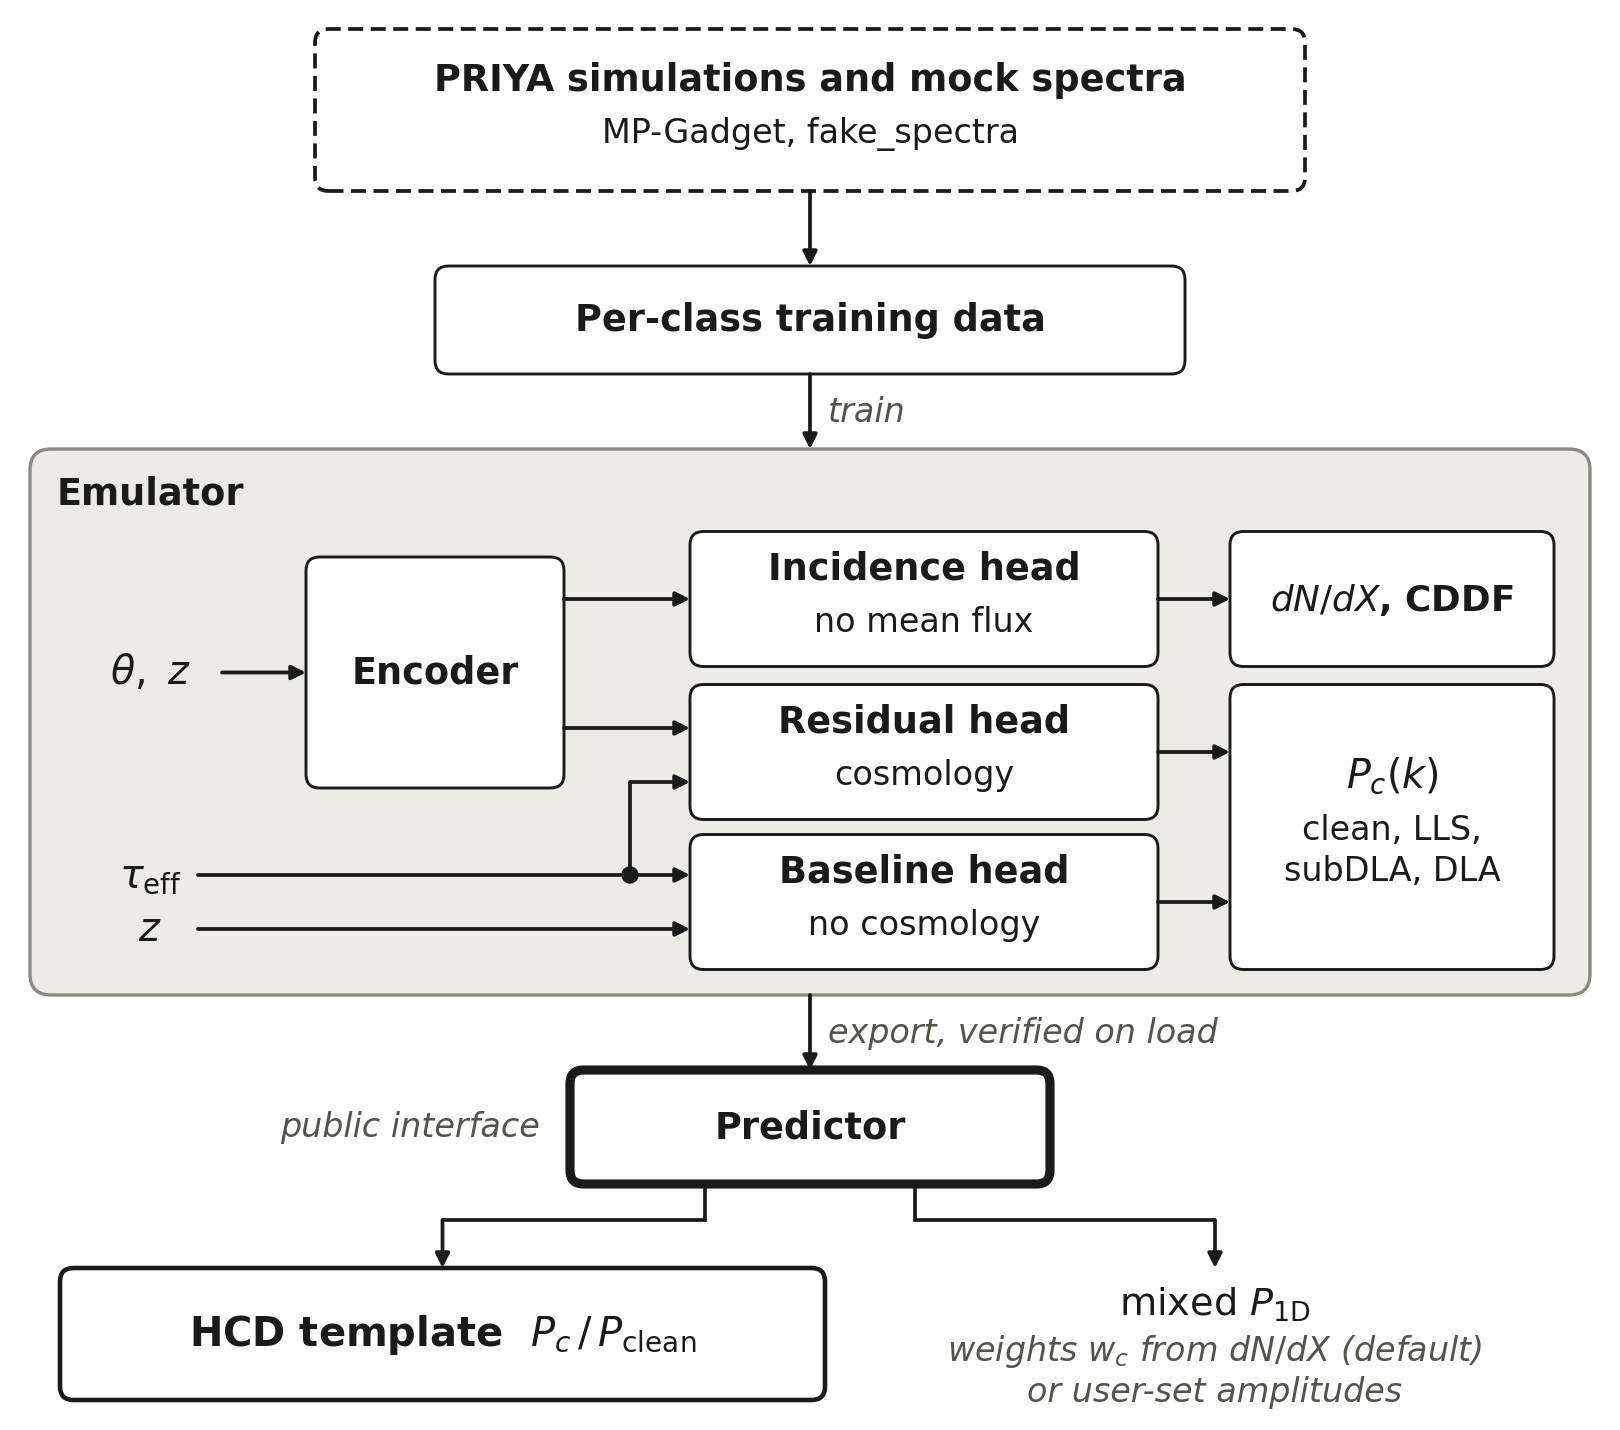

In [4]:
display(Image(filename="assets/figures/joss_architecture.png", width=900))

In [5]:
# z is a PRIYA snapshot redshift; tau0_amp = 1 and dtau0 = 0 give the mean flux of Kim et al. (2007).
pred = emu.predict(PARAMS, z=3.0, tau0_amp=1.0, dtau0=0.0)

print("classes, in the order of P_class:", hp.CLASSES)
print(f"pred.k: shape {pred.k.shape}, from {pred.k[0]:.2e} to {pred.k[-1]:.2e} s/km")
print(f"pred.P_class: shape {pred.P_class.shape}, in km/s")
print("pred.w_c, the sightline fractions of", hp.HCD_CLASSES, ":", np.round(pred.w_c, 4))
print("pred.dndx, the incidence dN/dX of the same classes:", np.round(pred.dndx, 4))
print("flags that are set:", sorted(name for name, value in pred.flags.items() if value is True))

classes, in the order of P_class: ('clean', 'LLS', 'subDLA', 'DLA')
pred.k: shape (172,), from 4.76e-04 to 8.18e-02 s/km
pred.P_class: shape (4, 172), in km/s
pred.w_c, the sightline fractions of ('LLS', 'subDLA', 'DLA') : [0.2126 0.0786 0.0376]
pred.dndx, the incidence dN/dX of the same classes: [0.4337 0.1343 0.0602]
flags that are set: ['incidence_heldout_error_available', 'incidence_mf_applied', 'k_downweighted', 'mf_applied', 'p1d_validation_available']


### Conventions

**UNAPPROVED (PI to review).**

- The spectrum is that of $\delta_F = F / \langle F \rangle - 1$, with one mean flux $\langle F \rangle$ for the
  whole sample of sightlines, all classes together.
- $k$ is the angular wavenumber, in s/km.
- The class spectra are *PRIYA-filtered*: the cores of the strongest absorbers are masked in the simulated
  spectra, as for the PRIYA forest emulator, and the mixture below does not add back what the filter removed
  (`pred.labels["omissions"]` names it).

A class spectrum is therefore a conditional spectrum under one normalisation. It is not the spectrum of isolated
absorbers. The definitions are in `docs/p1d_definition.md` of the repository.

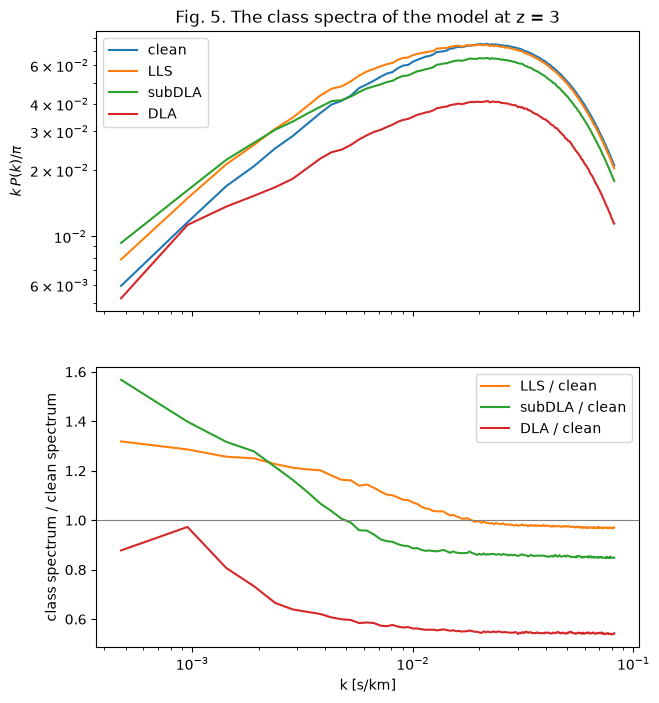

In [6]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(7, 8), sharex=True)
for i, name in enumerate(hp.CLASSES):
    top.loglog(pred.k, pred.k * pred.P_class[i] / np.pi, color=f"C{i}", label=name)
    if (
        name != "clean"
    ):  # each HCD class over the clean forest, the quantity a template of HCD absorbers models
        bottom.semilogx(
            pred.k, pred.P_class[i] / pred.P_class[0], color=f"C{i}", label=f"{name} / clean"
        )
bottom.axhline(1.0, color="grey", lw=0.8)
top.set_ylabel(r"$k\,P(k)/\pi$")
bottom.set_ylabel("class spectrum / clean spectrum")
bottom.set_xlabel("k [s/km]")
top.set_title("Fig. 5. The class spectra of the model at z = 3")
top.legend()
bottom.legend()
plt.show()

**UNAPPROVED (PI to review).** Reading Fig. 5: With the conventions above, a ratio below one is not a
defect: the classes share one mean flux, and the filter removes the core of the strongest absorbers. The physical
reading of each class is to be written here.

### The mixture of the classes

**UNAPPROVED (PI to review).** `hp.add_hcd(pred, A)` mixes the class spectra linearly:

$$P_\mathrm{mix}(k) = P_\mathrm{clean}(k) + \sum_c A_c\,[P_c(k) - P_\mathrm{clean}(k)], \qquad c \in \{\mathrm{LLS}, \mathrm{subDLA}, \mathrm{DLA}\}.$$

The amplitudes $A_c$ are fractions of sightlines. The model's own fractions at a point are `pred.w_c`.

What the mixture is not: it is not the P1D of an observed sample (the cores removed by the filter are left out,
see `pred.labels["omissions"]`); nothing is fitted; and it carries no law in redshift of its own.

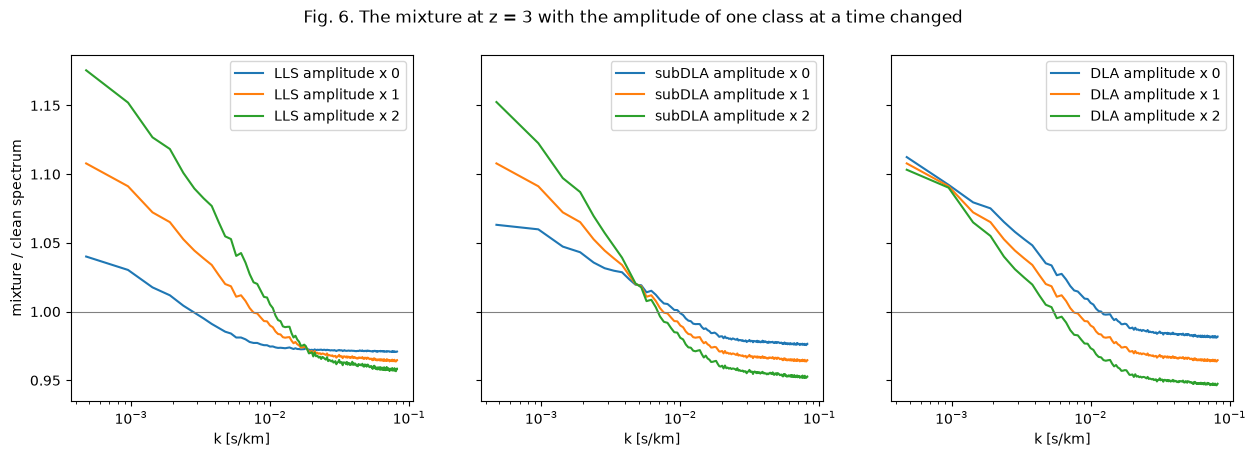

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for c, (ax, name) in enumerate(zip(axes, hp.HCD_CLASSES)):
    for factor in (0.0, 1.0, 2.0):
        amplitudes = pred.w_c.copy()
        amplitudes[
            c
        ] *= factor  # one class at a time; the other two stay at the model's own fractions
        mixture = hp.add_hcd(pred, amplitudes)
        ax.semilogx(pred.k, mixture / pred.P_class[0], label=f"{name} amplitude x {factor:g}")
    ax.axhline(1.0, color="grey", lw=0.8)
    ax.set_xlabel("k [s/km]")
    ax.legend()
axes[0].set_ylabel("mixture / clean spectrum")
fig.suptitle("Fig. 6. The mixture at z = 3 with the amplitude of one class at a time changed")
plt.show()

### The incidence of the absorbers

**UNAPPROVED (PI to review).** The model also predicts the incidence dN/dX of the three classes (`pred.dndx`), with a
held-out range (`pred.dndx_lower` to `pred.dndx_upper`), and the column density distribution.

In [8]:
for c, name in enumerate(hp.HCD_CLASSES):
    low, high = pred.dndx_lower[c], pred.dndx_upper[c]
    print(
        f"dN/dX of the {name} class at z = 3: {pred.dndx[c]:.4f}, held-out range {low:.4f} to {high:.4f}"
    )

dN/dX of the LLS class at z = 3: 0.4337, held-out range 0.4242 to 0.4435
dN/dX of the subDLA class at z = 3: 0.1343, held-out range 0.1314 to 0.1372
dN/dX of the DLA class at z = 3: 0.0602, held-out range 0.0595 to 0.0609


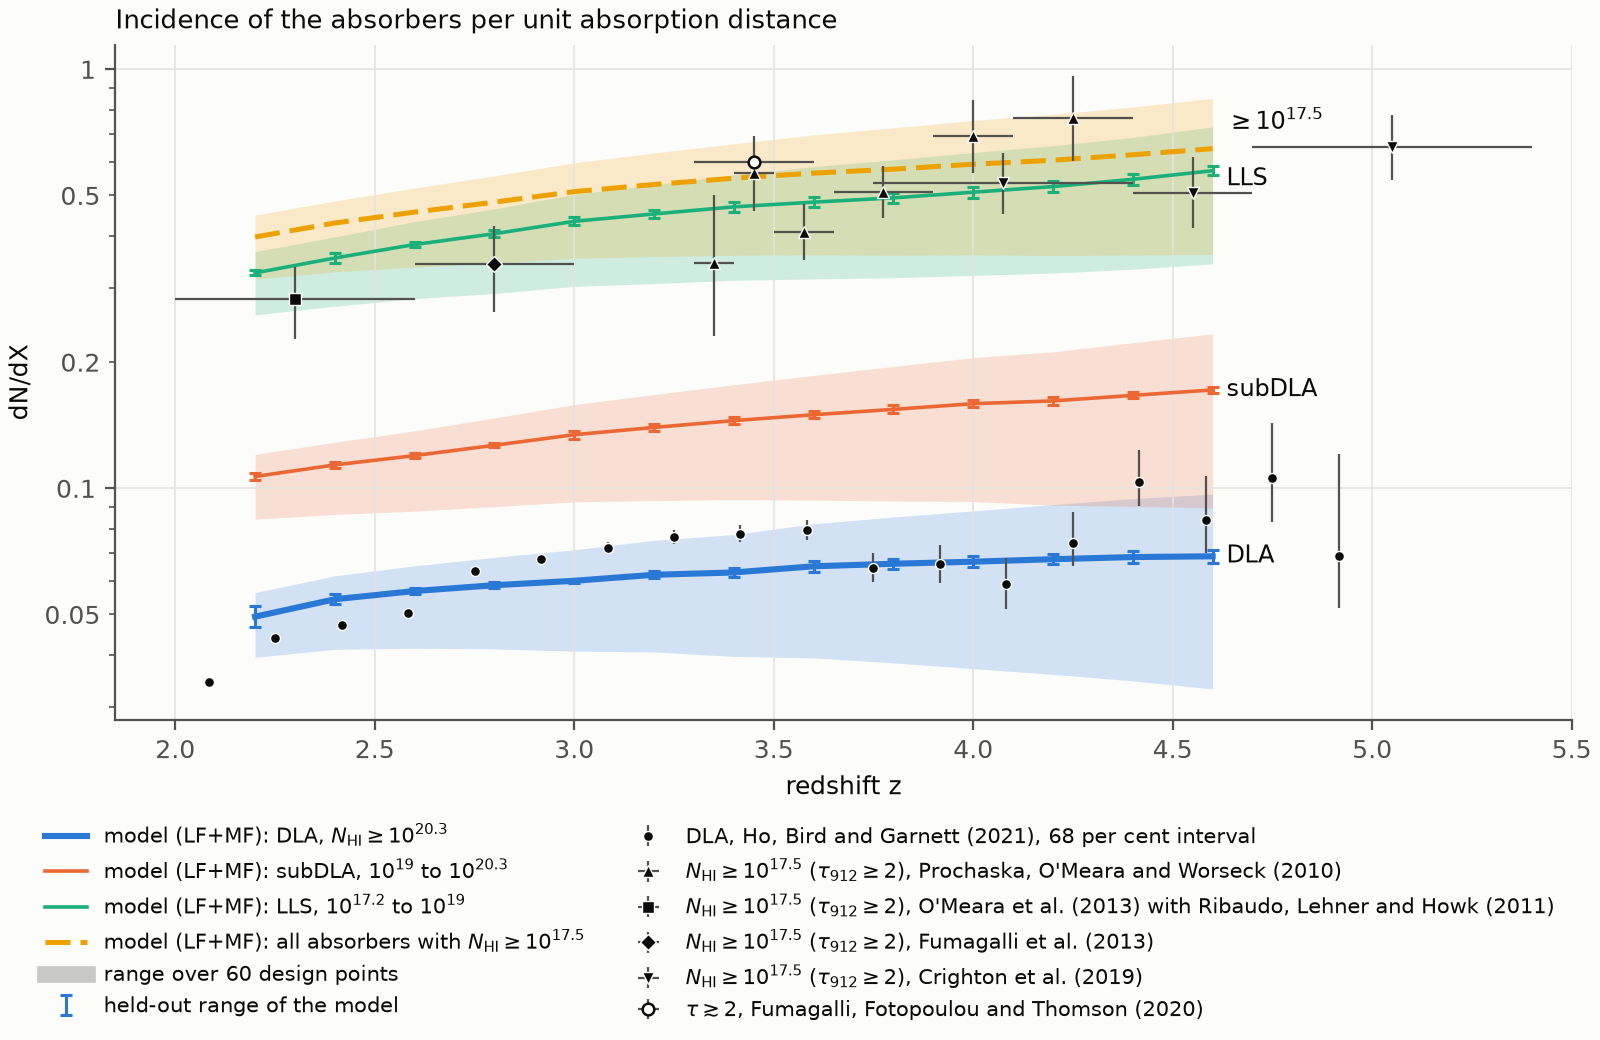

In [9]:
# The released figure script of the clone draws the figure; this notebook only runs it and shows the image.
# The script's own printed report is not shown; an error of the script still is.
script = "../../scripts/figures/fig_dndx_vs_ho21.py"
image = "tutorial_output/dndx_vs_ho21.png"
subprocess.run(
    [sys.executable, script, "--published", "--out", image], check=True, stdout=subprocess.DEVNULL
)
display(Image(filename=image, width=900))

**Fig. 7. UNAPPROVED (PI to review).** The incidence dN/dX the model predicts for the three classes, and for all
absorbers above $10^{17.5}$ cm$^{-2}$, against redshift, with published measurements. Drawn by the released script
`fig_dndx_vs_ho21.py`, unchanged; the full caption is in `docs/model_figures.md` of the repository.

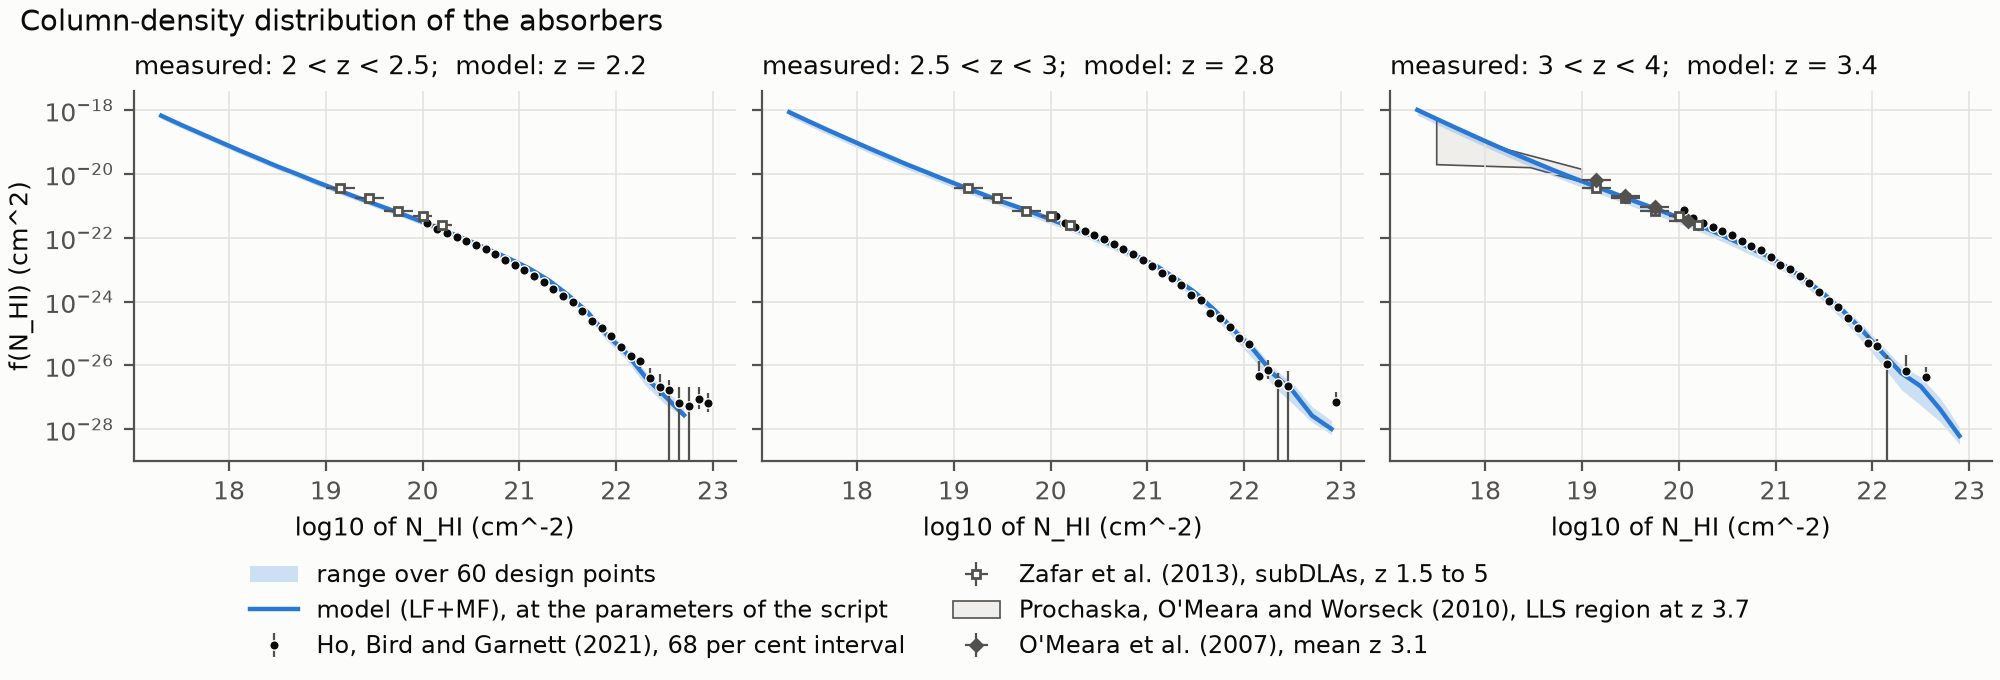

In [10]:
script = "../../scripts/figures/fig_cddf_vs_ho21.py"
image = "tutorial_output/cddf_vs_ho21.png"
subprocess.run(
    [sys.executable, script, "--published", "--out", image], check=True, stdout=subprocess.DEVNULL
)
display(Image(filename=image, width=900))

**Fig. 7b. UNAPPROVED (PI to review).** The column density distribution the model predicts, in three redshift
bins, with published measurements. Drawn by the released script `fig_cddf_vs_ho21.py`, unchanged;
the full caption is in `docs/model_figures.md` of the repository.

### How the incidence depends on the parameters

**UNAPPROVED (PI to review).** The next figure shows the predicted incidence of the LLS class at z = 3 while one of
four parameters at a time crosses the range it was trained on.

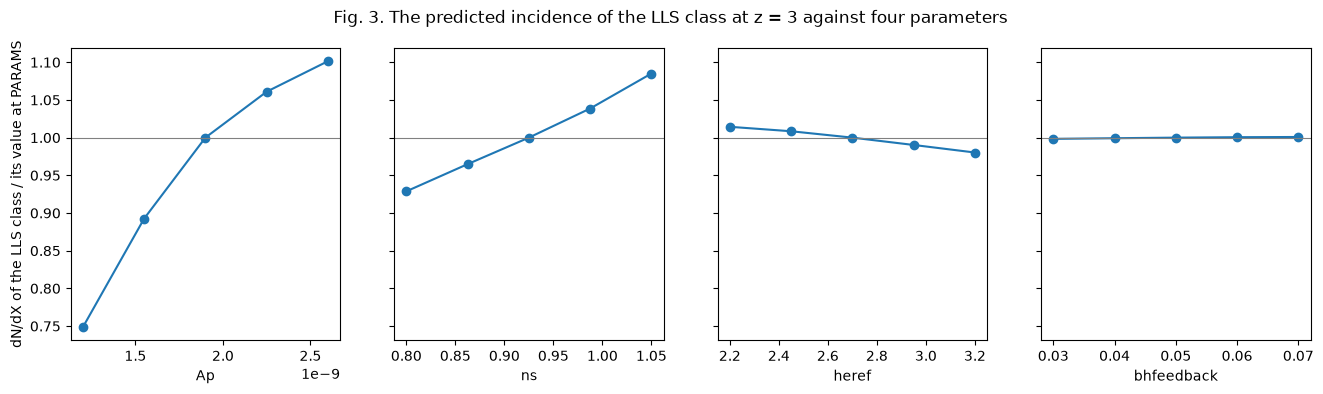

In [11]:
LLS = hp.HCD_CLASSES.index("LLS")  # the place of the LLS class in pred.dndx and pred.w_c
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, name in zip(axes, ("Ap", "ns", "heref", "bhfeedback")):
    low, high = hp.PARAM_LIMITS[hp.PARAM_NAMES.index(name)]
    values = np.linspace(low, high, 5)
    # one parameter crosses its trained range; the other eight and the mean flux stay as in PARAMS
    moved = [
        emu.predict({**PARAMS, name: value}, z=3.0, tau0_amp=1.0, dtau0=0.0) for value in values
    ]
    ax.plot(values, [p.dndx[LLS] / pred.dndx[LLS] for p in moved], "o-")
    ax.axhline(1.0, color="grey", lw=0.8)
    ax.set_xlabel(name)
axes[0].set_ylabel("dN/dX of the LLS class / its value at PARAMS")
fig.suptitle("Fig. 3. The predicted incidence of the LLS class at z = 3 against four parameters")
plt.show()

### Two different operations

**UNAPPROVED (PI to review).** There are two ways to change how much the LLS contribute to a mixture, and they
are not the same operation.

1. **Changing an amplitude $A_c$** rescales how many sightlines of a class enter the mixture, at fixed class
   spectra. No new prediction is made. The amplitude is a nuisance of the mixture.
2. **Changing the nine parameters** changes what the emulator predicts: the incidence (Fig. 3), the sightline
   fractions and the class spectra together. The incidence is a prediction.

The next cell does each once and prints what changes and what stays the same.

In [12]:
# (A) The LLS amplitude doubled by hand. No new prediction is made, so the incidence does not change.
doubled = pred.w_c.copy()
doubled[LLS] *= 2.0
# (B) One parameter moved. This is a new prediction, with its own incidence and sightline fractions.
pred_b = emu.predict({**PARAMS, "Ap": 2.6e-9}, z=3.0, tau0_amp=1.0, dtau0=0.0)

print("                      dN/dX of LLS   LLS amplitude in the mixture")
print(f"the prediction above  {pred.dndx[LLS]:.4f}         {pred.w_c[LLS]:.4f}")
print(f"(A) amplitude x 2     {pred.dndx[LLS]:.4f}         {doubled[LLS]:.4f}")
print(f"(B) Ap = 2.6e-9       {pred_b.dndx[LLS]:.4f}         {pred_b.w_c[LLS]:.4f}")

                      dN/dX of LLS   LLS amplitude in the mixture
the prediction above  0.4337         0.2126
(A) amplitude x 2     0.4337         0.4252
(B) Ap = 2.6e-9       0.4777         0.2276


### How far to trust it: the held-out prediction residual and the validated range

**UNAPPROVED (PI to review).** For each class spectrum and for the mixture the model carries a *held-out
prediction residual* $e(k)$: the root mean square of $\ln(\mathrm{prediction} / \mathrm{truth})$ over simulations
the model was made without. As a range on a spectrum it is the value times $\exp(-e)$ to the value times
$\exp(+e)$, each bound on its own. It is an empirical validation diagnostic, not a calibrated predictive
uncertainty.

The LF+MF model is validated from $z = 2.2$ to $4.6$. Above that range a prediction is returned with flags;
below it, and between snapshot redshifts, it is refused.

In [13]:
# e is the rms of ln(prediction / truth) over simulations the model was made without, one value per wavenumber.
e = pred.P_mix_validation_rms_log
median, largest = np.nanmedian(e), np.nanmax(e)
print(
    f"median e = {median:.3f}: the mixture times {np.exp(-median):.3f} to times {np.exp(median):.3f}"
)
print(
    f"largest e = {largest:.3f}: the mixture times {np.exp(-largest):.3f} to times {np.exp(largest):.3f}"
)

median e = 0.009: the mixture times 0.991 to times 1.009
largest e = 0.036: the mixture times 0.964 to times 1.037


In [14]:
# Above the validated range a prediction is returned with flags; between snapshot redshifts it is refused.
high = emu.predict(PARAMS, z=4.8, tau0_amp=1.0, dtau0=0.0)
set_at_3 = {name for name, value in pred.flags.items() if value is True}
set_at_48 = {name for name, value in high.flags.items() if value is True}
print("flags set at z = 4.8 and not at z = 3:", sorted(set_at_48 - set_at_3))
try:
    emu.predict(PARAMS, z=3.1, tau0_amp=1.0, dtau0=0.0)
except hp.PredictorInputError as error:
    print("z = 3.1 is refused:", error)

flags set at z = 4.8 and not at z = 3: ['mf_z_above_validated', 'w_c_xbar_extrapolated', 'z_downweighted']
z = 3.1 is refused: z = 3.1 is not a PRIYA snapshot redshift (2.0, 2.2, 2.4, 2.6, 2.8, 3.0, 3.2, 3.4, 3.6, 3.8, 4.0, 4.2, 4.4, 4.6, 4.8, 5.0, 5.2, 5.4) (tolerance 1e-09)


### Beside the template of Rogers et al. (2018)

**UNAPPROVED (PI to review; each statement about the paper is to be checked against it).** Rogers et al. (2018)
give a template for the effect of HCD absorbers on the P1D: for each of four classes of column density, a fitted
function of $k$ and $z$ for the ratio of the class spectrum to the forest spectrum (their Eq. 6), from one
simulation, used with free amplitudes and with no dependence on cosmology. What differs here: the class spectra
are emulated across nine parameters and the mean flux; they are PRIYA-filtered; and the incidence is predicted.
`docs/rogers_comparison.md` of the repository gives the comparison in full.

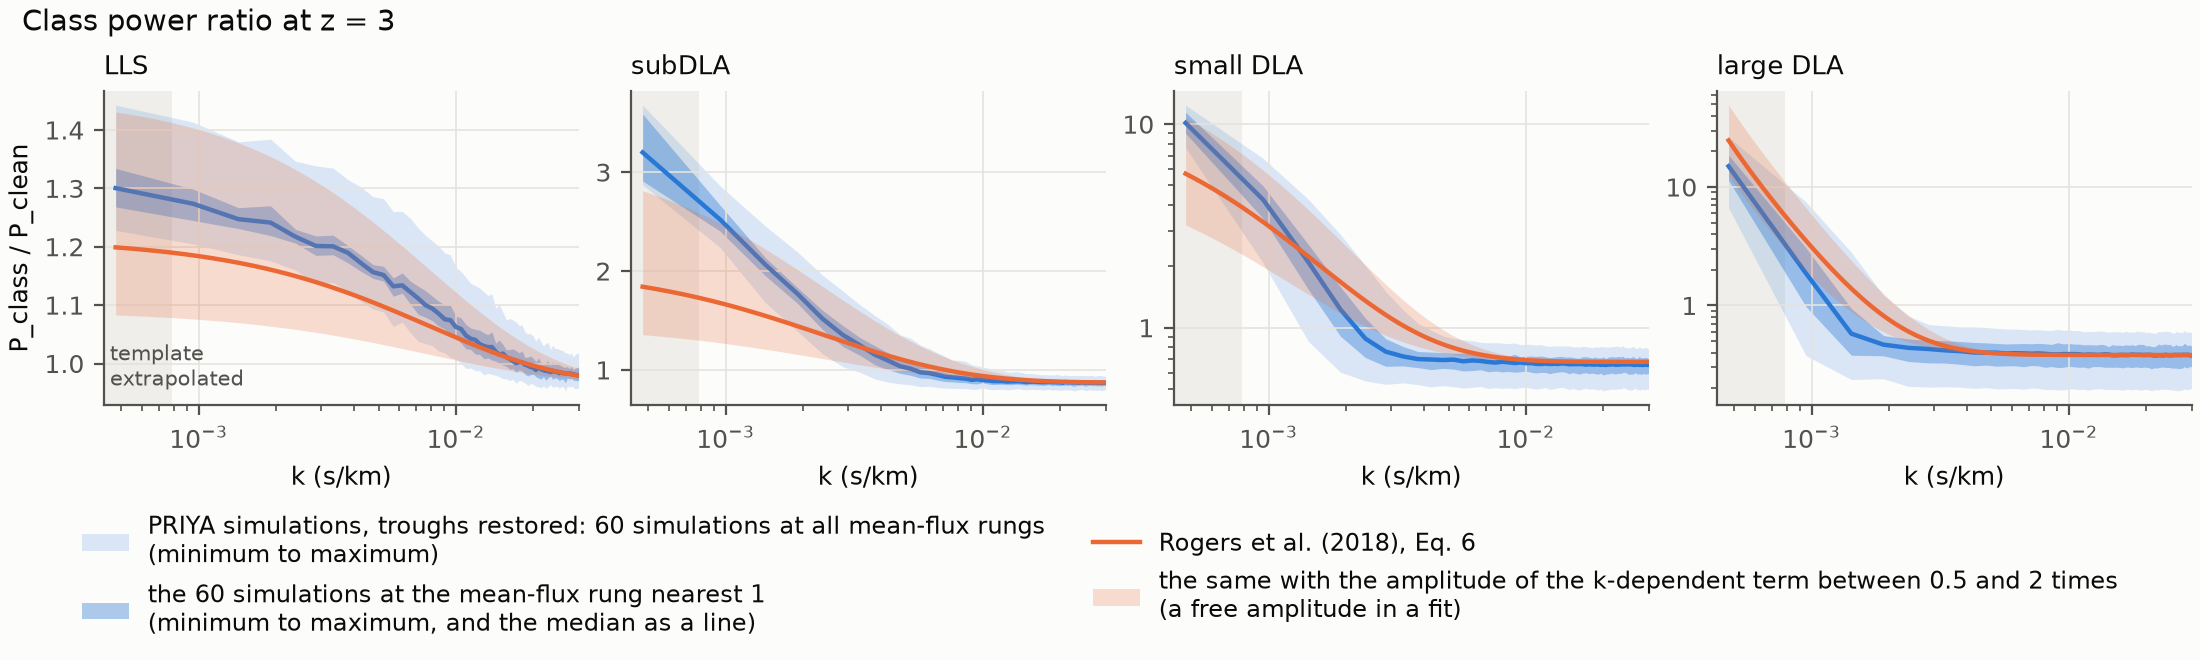

In [15]:
# This script needs no model: it draws the training simulations' class ratios from a table of the clone.
script = "../../scripts/figures/fig_class_ratio_vs_rogers18.py"
image = "tutorial_output/class_ratio_vs_rogers18.png"
subprocess.run([sys.executable, script, "--out", image], check=True, stdout=subprocess.DEVNULL)
display(Image(filename=image, width=900))

**Fig. 8. UNAPPROVED (PI to review).** Drawn by the released script `fig_class_ratio_vs_rogers18.py`, unchanged; the full caption is in
`docs/rogers_comparison.md` of the repository. The filtered troughs are restored, so levels can be compared with
the template.

## Part III. The public likelihood and the mock-recovery example

**UNAPPROVED (PI to review).** This part uses the package's own Gaussian likelihood and the mock-recovery example
of the repository, with the files of the release. Nothing is fitted here.

### The Gaussian likelihood

`hcd_analysis.likelihood.GaussianP1DLikelihood` compares a data vector $d$ with covariance $C$ to a model vector
$m(\theta)$:

$$\ln L(\theta) = -\tfrac{1}{2}\,[d - m(\theta)]^{T} C^{-1} [d - m(\theta)] - \tfrac{1}{2} \ln\det C - \tfrac{N}{2}\ln 2\pi .$$

The class builds the model vector in four steps: the prediction at $\theta$ at the redshifts of the data; the
mixture of the class spectra (`hp.add_hcd`); linear interpolation in $k$ to the wavenumbers of the data; and the
data set's own factor on the model, when it has one. `docs/likelihood.md` of the repository describes the class,
its options and its approximations.

In [16]:
sys.path.insert(
    0, "../../examples"
)  # the released example is a script of the clone, two folders up
import mock_recovery as example

# open_download reads the held-out model, the mock and the stored reference of the example,
# and checks each file as the released script does.
emu_heldout, data, reference = example.open_download("hcd_priya_example_download")
print(
    f"the mock: {data.n} bins at {len(data.z)} redshifts, from z = {min(data.z):.1f} to {max(data.z):.1f}"
)

the mock: 121 bins at 11 redshifts, from z = 2.2 to 4.2


**UNAPPROVED (PI to review).** Parts I and II use the published production model. Part III uses the held-out
model of the example download, because the mock-recovery example of the paper does: the mock comes from a
simulation, and the held-out model was trained without that simulation.

In [17]:
like = likelihood.GaussianP1DLikelihood(emu_heldout, data, gaussian_terms=example.GAUSSIAN_TERMS)
# The held-out model warns about its dN/dX and CDDF. A warning shown by Jupyter would also print where
# the package is installed on this machine, so it is caught here and its message is printed instead.
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    truth = example.part_one(like)
for warning in caught:
    print(f"{warning.category.__name__}: {warning.message}")

=== Part 1: the likelihood at the point the mock was made at
bins in the data vector: 121
redshifts: [4.2, 4.0, 3.8000000000000003, 3.6, 3.4000000000000004, 3.2, 3.0, 2.8, 2.6, 2.4000000000000004, 2.2]
the truth, by name: {'ns': 0.909475936, 'Ap': 1.98137389e-09, 'herei': 3.75465601, 'heref': 3.00952068, 'alphaq': 2.43025565, 'hub': 0.681591829, 'omegamh2': 0.1403, 'hireionz': 7.60269787, 'bhfeedback': 0.0448727377, 'tau0_amp': 1.011182770662847, 'dtau0': 0.0}
parameters of the truth outside this example's flat boxes: []


flags set at the truth (read them before you use the numbers): ['cddf_bins_without_support', 'incidence_mf_applied', 'k_downweighted', 'mf_applied', 'research_content_checks', 'research_model', 'research_split']
the model's class fractions (LLS, subDLA, DLA) at the first redshift, used for the mixture: [0.34086566594878925, 0.14880670702148607, 0.07102776219984568]
model mode spacings per bin spacing, the smallest over all bins and redshifts (likelihood.modes_per_bin; a report of the bin layout, not a test of the interpolation): 4.27
chi-square at the truth (0 would mean the model reproduces the mock exactly): 1.5008160153271053
chi-square per bin at the truth: 0.012403438143199217
log likelihood at the truth, with its normalisation: -93.16361048340667
log density of each Gaussian term at the truth: {'hub': 2.12129231466528, 'bhfeedback': 3.6743996759032833}


**UNAPPROVED (PI to review).** The warning printed above comes from the held-out model. It concerns the dN/dX
and the column density distribution of that model, which carry no held-out error. The likelihood uses neither.

In [18]:
print("three evaluations of the public likelihood at the mock's truth;")
print("nothing is fitted and these are not constraints")
for r_lls in (0.0, 1.0, 2.0):
    # hcd_relative_to_priya sets the amplitude of a class relative to the model's own sightline fraction
    relative = {"LLS": r_lls, "subDLA": 1.0, "DLA": 1.0}
    scaled = likelihood.GaussianP1DLikelihood(
        emu_heldout, data, gaussian_terms=example.GAUSSIAN_TERMS, hcd_relative_to_priya=relative
    )
    print(
        f"LLS amplitude at {r_lls:g} times the model's own fraction: chi-square = {scaled.chi2(truth):.4f}"
    )

three evaluations of the public likelihood at the mock's truth;
nothing is fitted and these are not constraints
LLS amplitude at 0 times the model's own fraction: chi-square = 2.9302


LLS amplitude at 1 times the model's own fraction: chi-square = 1.5008
LLS amplitude at 2 times the model's own fraction: chi-square = 4.8629


figure written: tutorial_output/posterior_intervals.png


figure written: tutorial_output/posterior_predictive_per_redshift.png


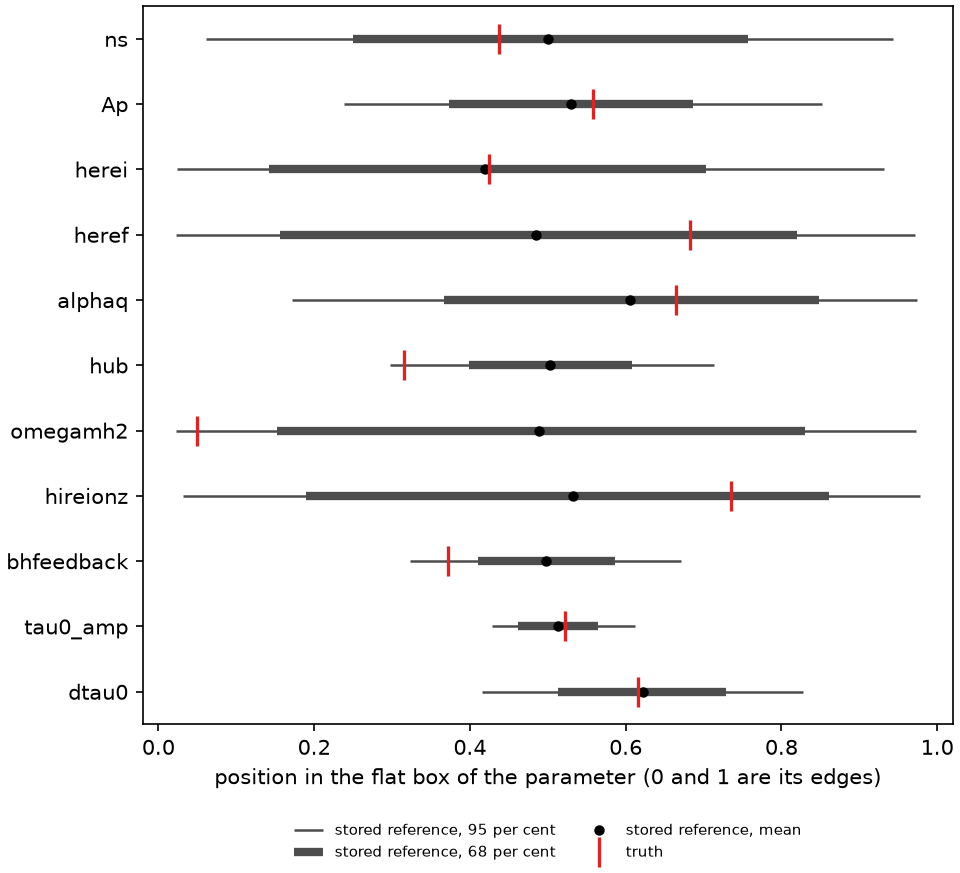

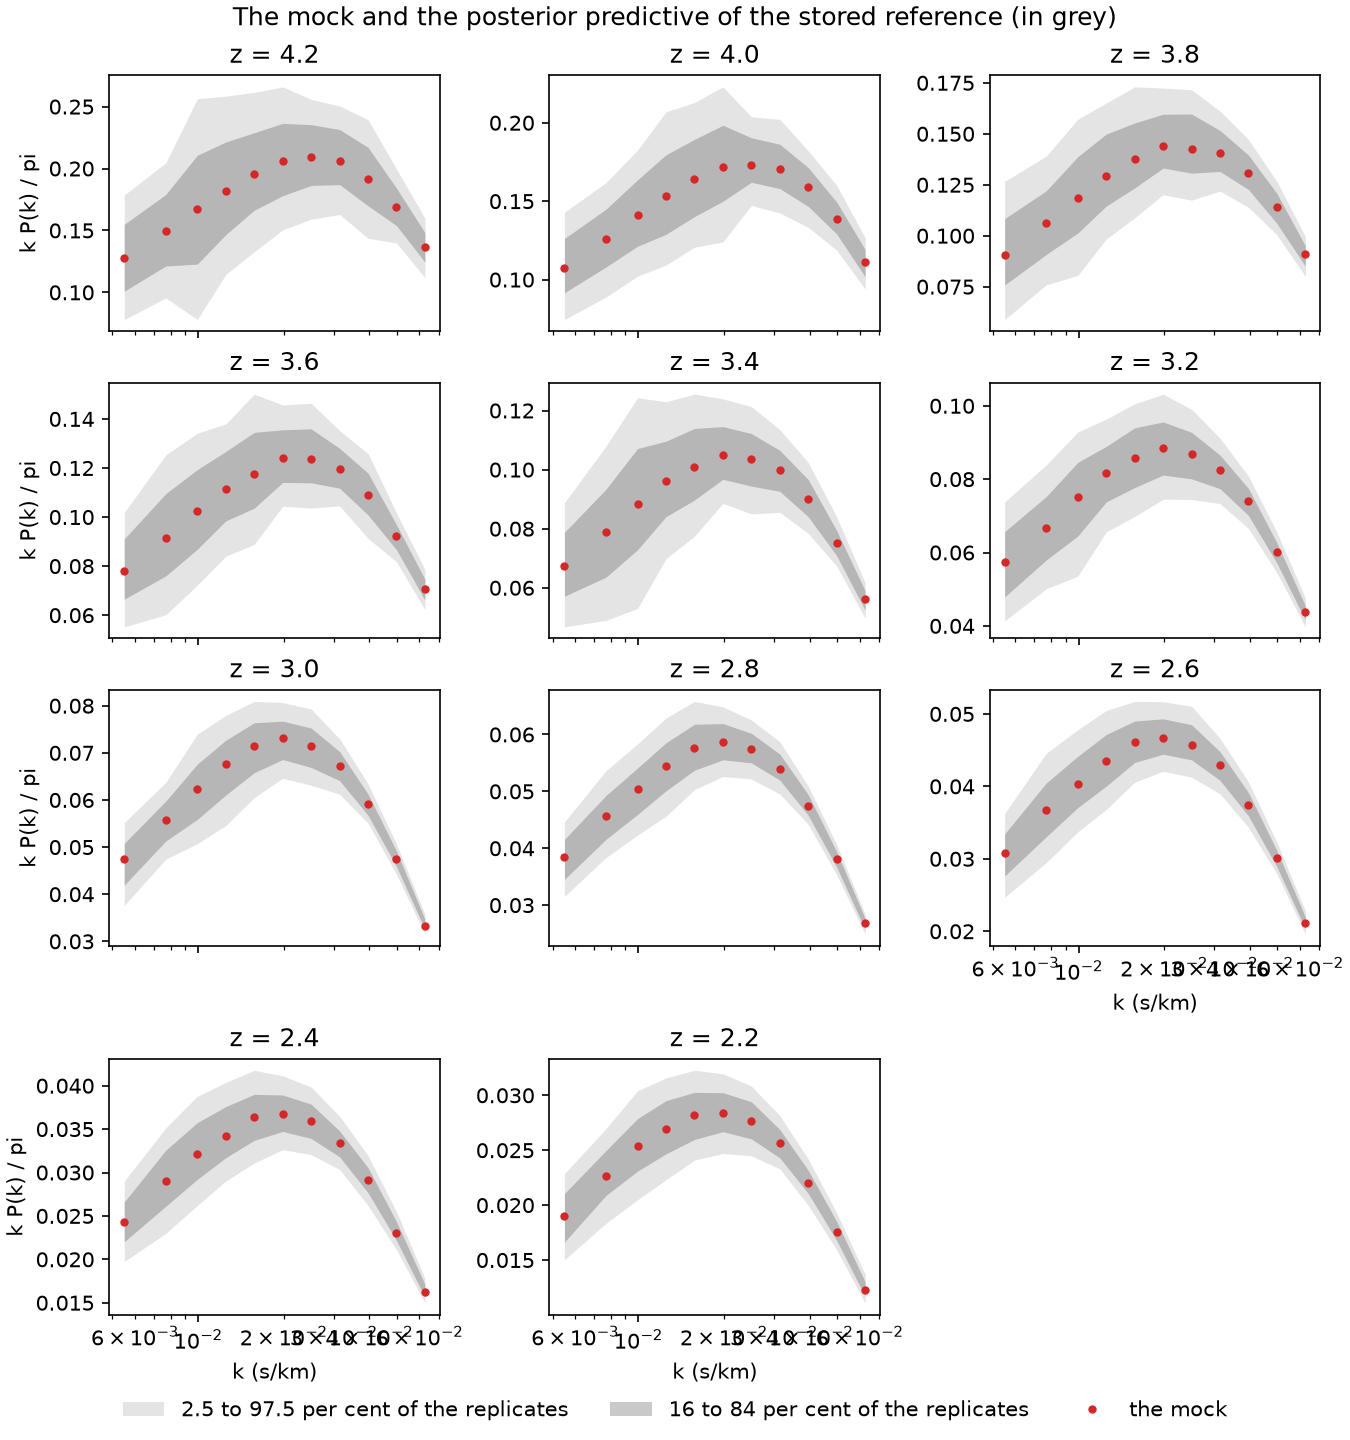

In [19]:
# The example draws both figures from the stored reference and the mock alone, and saves them as files.
intervals_png, per_redshift_png = example.draw_reference(reference, data, "tutorial_output")
plt.close("all")
display(Image(filename=intervals_png, width=800))
display(Image(filename=per_redshift_png, width=900))

**Fig. 9 (the paper's Figure 4). UNAPPROVED (PI to review).** For each of the eleven parameters, the mean and the
central 68 and 95 per cent intervals of the stored reference, with the truth of the mock. Redrawn here from the
stored reference of the release (a summary of converged chains made before the release); not recomputed.

**Fig. 10. UNAPPROVED (PI to review).** The mock and the stored bands of the posterior predictive of the
reference, one panel per redshift. Redrawn here from the stored reference of the release (a summary of converged
chains made before the release); not recomputed.

### What can and cannot be reproduced

**UNAPPROVED (PI to review).**

| Result | From the published release? |
|---|---|
| Every figure of Parts I and II; the likelihood at the truth of the mock; the three chi-square values | computed when the notebook runs |
| The reference posterior of the mock (the paper's Figure 4; Fig. 9 and 10 here) | read from the stored reference of the release, a summary of converged chains made before the release; not recomputed |
| A chain of one's own on the mock | outside this notebook: `python examples/mock_recovery.py --download DIR --full`, which needs Cobaya; not run here |
| The contours of the paper's Figure 3 and its comparison with the Gaussian-process emulator | cannot be fully reproduced from the public files, because the chains are not public |

## Limits, and where to go next

**UNAPPROVED (PI to review).**

- Part III evaluates the public likelihood at the truth of a mock and redraws a stored result. Nothing in this
  notebook is fitted, and nothing here is a constraint from data.
- The likelihood uses the covariance of the data alone. The held-out prediction residual of Part II is an
  empirical validation diagnostic, not a calibrated predictive uncertainty, and it does not enter the likelihood.
- The class spectra are PRIYA-filtered, and the mixture leaves out what the filter removed.

Where to go next, in the repository: `docs/likelihood.md` (the likelihood, its options and what it refuses);
`examples/mock_recovery.py` (the example used above, with its chain modes); `docs/model_figures.md` (the model
against published measurements); `docs/p1d_definition.md` (the conventions).